# Lecture 1 — The Pantheon+ fit with cmbagent_lg, traced with Langfuse

*Multi-Agent Systems for Science · Boris Bolliet, University of Cambridge*<br>
*Companion to `lecture01.ipynb`*

This notebook gives the analysis of `lecture01.ipynb`, the flat-ΛCDM fit of $\Omega_m$ to the Pantheon+ supernovae, to [cmbagent_lg](https://github.com/CMBAgents/cmbagent/tree/lg), the LangGraph implementation of CMBAgent. It runs the task the way the analysis stage of Denario does: `planning_graph` writes a plan, and `deep_research_graph` executes it step by step. A `PlanContext` object holds the task, the model of each role and the limits of the run.

[Langfuse](https://langfuse.com/docs) records every model call of the run as part of a trace. The notebook reads the trace back through the Langfuse API and computes the bill of each agent. A local ledger records the same calls in the notebook, so the bill is also available without Langfuse.

## Setup

The notebook needs a key for the Gemini API (Google AI Studio). On Colab, store it as a secret named `GOOGLE_API_KEY`; elsewhere, set the environment variable before starting Jupyter.

The first cell installs cmbagent_lg from the `lg` branch of the CMBAgent repository, with Langfuse and the scientific packages, into the environment of the kernel, on Colab or locally. From a terminal, the same installation is `pip install "cmbagent_lg @ git+https://github.com/CMBAgents/cmbagent@lg" langfuse numpy scipy pandas matplotlib`; `requirements_lg.txt` pins the versions of the saved run.

Tracing is optional. To trace the run, create a free project on [Langfuse Cloud](https://cloud.langfuse.com), create an API key pair in its settings, and set three secrets or environment variables:

| Name | Value |
|---|---|
| `LANGFUSE_PUBLIC_KEY` | the public key, `pk-lf-…` |
| `LANGFUSE_SECRET_KEY` | the secret key, `sk-lf-…` |
| `LANGFUSE_BASE_URL` | `https://cloud.langfuse.com` (EU region) or `https://us.cloud.langfuse.com` (US region) |

The tracing server receives the prompts of every call, including the task text, the scripts, their printed output and the replies of the model. Do not trace data that may not leave your machine.

cmbagent_lg runs each model-written script in a subprocess that inherits the environment of the kernel, so a script can read the API keys set in this notebook. Run the notebook on Colab or in a container that holds only the keys it needs. In the saved notebook, the two runs took 437 s and 177 s and made 27 and 20 model calls, and the engineer's reasoning tokens make up most of the output tokens.

In [ ]:
%pip install -q "cmbagent_lg @ git+https://github.com/CMBAgents/cmbagent@lg" langfuse numpy scipy pandas matplotlib

In [2]:
%matplotlib inline
import base64, contextlib, json, os, platform, re, shutil, sys, tempfile, threading, time
import urllib.parse, urllib.request, warnings
from collections import Counter, defaultdict
from datetime import datetime, timedelta, timezone
from importlib.metadata import version
from pathlib import Path

warnings.filterwarnings("ignore", category=SyntaxWarning)  # emitted by google-genai when it is first compiled
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from langchain_core.callbacks import BaseCallbackHandler
from scipy.integrate import cumulative_trapezoid
from scipy.linalg import cho_factor, cho_solve
from scipy.optimize import brentq, minimize_scalar
from cmbagent_lg import PlanContext, deep_research_graph, graph as planning_graph, prepare_work_dir
from cmbagent_lg.tracing import langfuse_callbacks


def installed(package):
    try:
        return version(package)
    except Exception:
        return None


VERSIONS = {"python": platform.python_version()} | {p: installed(p) for p in [
    "cmbagent_lg", "langgraph", "langchain", "langchain-core", "langchain-google-genai", "google-genai",
    "langfuse", "numpy", "scipy", "pandas", "matplotlib"]}
print(VERSIONS)

INK, MUTED, BLUE, ORANGE, AQUA = "#0b0b0b", "#8c8b86", "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "font.size": 10, "axes.titlesize": 10, "axes.labelcolor": INK, "axes.edgecolor": "#52514e",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": 0.6, "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
    "savefig.bbox": "tight"})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
FIG_DIR = Path("../figures") if Path("../figures").is_dir() else Path("figures")
RESULTS_DIR = Path("results")
for directory in (FIG_DIR, RESULTS_DIR):
    directory.mkdir(exist_ok=True)


def save_figure(fig, name):
    for suffix in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{suffix}", dpi=200)

{'python': '3.12.12', 'cmbagent_lg': '0.0.1', 'langgraph': '1.2.22', 'langchain': '1.5.0', 'langchain-core': '1.8.1', 'langchain-google-genai': '4.5.0', 'google-genai': '3.3.0', 'langfuse': '5.2.0', 'numpy': '2.5.4', 'scipy': '1.18.1', 'pandas': '3.1.1', 'matplotlib': '3.11.2'}


### Model and run settings

cmbagent_lg takes one model per role: planner, plan reviewer, engineer, researcher, evaluator and formatter. It infers the provider from the model name: `gemini-*` for Google, `gpt-*` for OpenAI, `claude-*` for Anthropic, each with its own API key. Here every role uses the model of `lecture01.ipynb`. cmbagent_lg sets the temperature and the thinking level of each role in `cmbagent_lg.llms`; the engineer runs with the thinking level `high`, and `PlanContext` has no setting to change it. The trace in §5 shows what this costs.

After each step, an adaptive review decides whether to rewrite the steps that have not run yet. cmbagent_lg gives this review its own models, set through the environment; the next cell sets them to the same model.

`RUNS` sets the number of complete runs, each with a plan of its own. The other settings bound a run: the number of plan steps, the attempts of the engineer at one step and the time of one script.

In [3]:
MODEL = "gemini-3.1-flash-lite"   # every role
# cmbagent_lg pins the adaptive review of the plan to non-lite models, gemini-3.1-pro-preview to review
# and gemini-3.6-flash to rewrite the remaining steps, because a lite reviewer triggers rewrites too often.
# Only the environment overrides them; here they use MODEL as well. Remove the two lines to restore them.
os.environ["ADAPTIVE_REVIEWER_MODEL"] = MODEL
os.environ["ADAPTIVE_PLANNER_MODEL"] = MODEL
RUNS = 2              # complete runs (planning and execution); 1 on a free-tier key
MAX_STEPS = 4         # maximum number of steps in a plan
MAX_ATTEMPTS = 3      # engineer attempts per step (self-debugging)
EXEC_TIMEOUT = 120    # seconds allowed to one script
TOLERANCE = 0.005     # agreement with the reference value of Omega_m, as in lecture01

In [4]:
def secret(name):
    # A Colab secret if one exists, else an environment variable, else None.
    try:
        from google.colab import userdata
        try:
            return userdata.get(name)
        except Exception:
            return os.environ.get(name)
    except ImportError:
        return os.environ.get(name)


os.environ["GOOGLE_API_KEY"] = secret("GOOGLE_API_KEY") or ""
os.environ.pop("GEMINI_API_KEY", None)     # the client prints a notice when both variables are set
assert os.environ["GOOGLE_API_KEY"], "Set GOOGLE_API_KEY as a Colab secret or as an environment variable."
for name in ("LANGFUSE_PUBLIC_KEY", "LANGFUSE_SECRET_KEY", "LANGFUSE_BASE_URL"):
    if secret(name):
        os.environ[name] = secret(name)
if os.environ.get("LANGFUSE_BASE_URL"):
    os.environ["LANGFUSE_HOST"] = os.environ["LANGFUSE_BASE_URL"]   # read by cmbagent-lg-cost

TRACED = all(os.environ.get(k) for k in ("LANGFUSE_PUBLIC_KEY", "LANGFUSE_SECRET_KEY", "LANGFUSE_BASE_URL"))
if TRACED:
    try:
        from langfuse import get_client
        TRACED = get_client().auth_check()           # wrong keys or URL: the traces would be lost silently
    except Exception as error:
        TRACED = False
        print("Langfuse check failed:", type(error).__name__)
LANGFUSE_CLOUD = os.environ.get("LANGFUSE_BASE_URL", "").rstrip("/") in (
    "https://cloud.langfuse.com", "https://us.cloud.langfuse.com")
print("Langfuse tracing:", "on" if TRACED else "off")

Langfuse tracing: on


## 1. Data and reference fit

The data, the cut $z_\mathrm{HD} > 0.01$ and the conventions are those of `lecture01.ipynb`, §1. The next cell downloads the two Pantheon+ files and repeats the deterministic fit with the full statistical and systematic covariance matrix, which gives the reference value for grading.

In [5]:
DATA_URL = "https://raw.githubusercontent.com/PantheonPlusSH0ES/DataRelease/main/Pantheon%2B_Data/4_DISTANCES_AND_COVAR/"
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
TABLE_PATH = (DATA_DIR / "Pantheon+SH0ES.dat").resolve()
COV_PATH = (DATA_DIR / "Pantheon+SH0ES_STAT+SYS.cov").resolve()
for path, remote in [(TABLE_PATH, "Pantheon%2BSH0ES.dat"), (COV_PATH, "Pantheon%2BSH0ES_STAT%2BSYS.cov")]:
    if not path.exists():
        partial = path.with_suffix(".part")
        urllib.request.urlretrieve(DATA_URL + remote, partial)
        partial.rename(path)

table = pd.read_csv(TABLE_PATH, sep=r"\s+")
values = np.loadtxt(COV_PATH)
cov = values[1:].reshape(int(values[0]), int(values[0]))
C_KM_S, H0 = 299792.458, 70.0


def reference_fit():
    # Omega_m with the full covariance and the offset M minimised analytically (lecture01, §1.3).
    keep = (table.zHD > 0.01).to_numpy()
    m, z, z_hel = (table.loc[keep, c].to_numpy() for c in ("m_b_corr", "zHD", "zHEL"))
    factor = cho_factor(cov[np.ix_(keep, keep)])
    ones = np.ones(len(m))
    ones_C_ones = ones @ cho_solve(factor, ones)

    def chi2(omega_m):
        grid = np.linspace(0.0, z.max() * 1.001, 20001)
        D_C = cumulative_trapezoid(1 / np.sqrt(omega_m * (1 + grid) ** 3 + 1 - omega_m), grid, initial=0) * C_KM_S / H0
        r = m - 5 * np.log10((1 + z_hel) * np.interp(z, grid, D_C)) - 25
        C_r = cho_solve(factor, r)
        return r @ C_r - (ones @ C_r) ** 2 / ones_C_ones

    best = minimize_scalar(chi2, bounds=(0.01, 0.99), method="bounded", options={"xatol": 1e-6})
    lower = brentq(lambda x: chi2(x) - best.fun - 1, 0.001, best.x)
    upper = brentq(lambda x: chi2(x) - best.fun - 1, best.x, 0.999)
    return {"omega_m": best.x, "omega_m_err": (upper - lower) / 2, "chi2_min": best.fun, "n_sn": int(keep.sum())}


REFERENCE = reference_fit()
print(f"Reference: Omega_m = {REFERENCE['omega_m']:.4f} ± {REFERENCE['omega_m_err']:.4f}, "
      f"chi2_min = {REFERENCE['chi2_min']:.1f}, {REFERENCE['n_sn']} light curves")


def grade(omega_m, omega_m_err):
    if omega_m is None:
        return "no result"
    if abs(omega_m - REFERENCE["omega_m"]) > TOLERANCE:
        return "wrong"
    if omega_m_err is None or abs(omega_m_err - REFERENCE["omega_m_err"]) > TOLERANCE:
        return "wrong error"
    return "correct"

Reference: Omega_m = 0.3316 ± 0.0182, chi2_min = 1402.9, 1590 light curves


## 2. Task and run context

Denario passes cmbagent_lg its description of the data as `main_task`. Here the task is the text of `lecture01.ipynb`, §1.4, with one difference: each run copies the two files into `data/` in its working directory, and the task names them there. cmbagent_lg looks for the inputs of a run under `data/`: before the engineer's first attempt at a step, its pre-flight check inspects the files there and reports their format to the engineer. Every script runs with the working directory as its current directory.

The context below selects the model of every role. It switches off the two optional parts of cmbagent_lg: the review of figures by a vision model (`vlm_enabled`) and the escalation of failures to a Claude agent (`enable_escalation`). The plan gets one review, as in Denario (`num_rounds=1`). The engineer is asked to print the result on a `RESULT` line, which the notebook reads to grade the run.

In [6]:
TASK = '''Measure the matter density Omega_m of a flat LCDM cosmology from the Pantheon+ type Ia supernovae.

Data
- Table: data/Pantheon+SH0ES.dat (in the working directory)
  Whitespace-separated with one header row; columns include zHD, zHEL, zCMB, m_b_corr, m_b_corr_err_DIAG, RA, DEC.
- Covariance: data/Pantheon+SH0ES_STAT+SYS.cov (in the working directory)
  Statistical plus systematic covariance of m_b_corr. The first line is N = 1701; the N*N entries follow,
  one per line, in row-major order; rows and columns follow the rows of the table.

Requirements
1. Use the light curves (table rows) with zHD > 0.01.
2. Model: m_b_corr = 5 log10(d_L / Mpc) + 25 + M, with d_L = (1 + zHEL) D_C(zHD) and D_C the comoving distance of a flat LCDM cosmology with H0 = 70 km/s/Mpc.
3. M is a free offset: minimise chi^2 over M analytically at each Omega_m.
4. Weight the residuals with the full statistical and systematic covariance matrix, restricted to the rows and columns of the selected supernovae.
5. Report Omega_m, its 1-sigma uncertainty from Delta chi^2 = 1, chi^2 at the minimum and the number of light curves (table rows) used.'''

RESULT_LINE = ('Use only numpy, scipy, pandas and matplotlib. When a script computes Omega_m, its last printed line must be '
               'RESULT {"omega_m": <value>, "omega_m_err": <value>, "chi2_min": <value>, "n_sn": <value>}')


def make_context():
    return PlanContext(
        main_task=TASK, maximum_number_of_steps_in_plan=MAX_STEPS, num_rounds=1, max_n_attempts=MAX_ATTEMPTS,
        code_execution_timeout=EXEC_TIMEOUT, vlm_enabled=False, enable_escalation=False,
        planner_model=MODEL, plan_reviewer_model=MODEL, engineer_model=MODEL, researcher_model=MODEL,
        evaluator_model=MODEL, formatter_model=MODEL, engineer_append_instructions=RESULT_LINE)


CONTEXT = make_context()
SETTINGS = {k: getattr(CONTEXT, k) for k in (
    "maximum_number_of_steps_in_plan", "num_rounds", "max_n_attempts", "code_execution_timeout", "vlm_enabled",
    "enable_escalation", "adaptive_planning", "researcher_mode", "planner_model", "plan_reviewer_model",
    "engineer_model", "researcher_model", "evaluator_model", "formatter_model")}
SETTINGS |= {k.lower(): os.environ[k] for k in ("ADAPTIVE_REVIEWER_MODEL", "ADAPTIVE_PLANNER_MODEL")}
print(json.dumps(SETTINGS, indent=1))

{
 "maximum_number_of_steps_in_plan": 4,
 "num_rounds": 1,
 "max_n_attempts": 3,
 "code_execution_timeout": 120,
 "vlm_enabled": false,
 "enable_escalation": false,
 "adaptive_planning": true,
 "researcher_mode": "react",
 "planner_model": "gemini-3.1-flash-lite",
 "plan_reviewer_model": "gemini-3.1-flash-lite",
 "engineer_model": "gemini-3.1-flash-lite",
 "researcher_model": "gemini-3.1-flash-lite",
 "evaluator_model": "gemini-3.1-flash-lite",
 "formatter_model": "gemini-3.1-flash-lite",
 "adaptive_reviewer_model": "gemini-3.1-flash-lite",
 "adaptive_planner_model": "gemini-3.1-flash-lite"
}


## 3. Callbacks: the Langfuse handler and a local ledger

LangChain passes callbacks from the configuration of `graph.invoke` to every model call inside the graph, including the calls of nested graphs. cmbagent_lg tags each call with the name of the agent that made it: `planner`, `engineer`, `execution_evaluator` and so on. Two callbacks receive every call:

- `langfuse_callbacks()` returns the Langfuse handler when the keys are set and an empty list otherwise. The handler sends each call to the tracing server. The metadata `langfuse_session_id` groups the two traces of one run, planning and execution, into one session.
- `CallLedger`, defined below, keeps the agent, the start and end times and the tokens of each call in the notebook. It prints one line per call, so the cell shows the run as it progresses.

cmbagent_lg also prints its own progress messages; the run writes them to `engine_output.txt` in its working directory.

In [7]:
AGENTS = ("planner", "plan_reviewer", "format_plan", "format_review", "intent_gate", "input_sourced_classifier",
          "engineer", "format_engineer", "execution_evaluator", "step_evaluator", "data_fixer", "escalation",
          "researcher", "react_researcher", "researcher_step_evaluator", "researcher_claim_auditor",
          "researcher_view_image", "image_reviewer", "adaptive_review", "format_adaptive_review", "replan_tail",
          "format_tail")


def agent_of(tags, metadata=None):
    return next((t for t in tags or [] if t in AGENTS), (metadata or {}).get("langgraph_node") or "other")


class CallLedger(BaseCallbackHandler):
    # Model calls of one run: agent, start and end in seconds from the start of the run, tokens.

    def __init__(self):
        self.start, self.calls, self.pending = time.perf_counter(), [], {}
        self.lock, self.out = threading.Lock(), sys.stdout    # sys.stdout before any redirection

    def on_chat_model_start(self, serialized, messages, *, run_id, tags=None, metadata=None, **kwargs):
        with self.lock:
            self.pending[run_id] = (agent_of(tags, metadata), time.perf_counter() - self.start)

    def on_llm_end(self, response, *, run_id, **kwargs):
        agent, t0 = self.pending.pop(run_id, ("other", None))
        generation = response.generations[0][0] if response.generations and response.generations[0] else None
        usage = getattr(getattr(generation, "message", None), "usage_metadata", None) or {}
        call = {"agent": agent, "t0": t0, "t1": time.perf_counter() - self.start,
                "input_tokens": usage.get("input_tokens", 0), "output_tokens": usage.get("output_tokens", 0),
                "reasoning_tokens": (usage.get("output_token_details") or {}).get("reasoning", 0)}
        with self.lock:
            self.calls.append(call)
        print(f"{call['t1']:7.1f} s  {agent:24s} in {call['input_tokens']:>7,}  out {call['output_tokens']:>7,}"
              f"  (reasoning {call['reasoning_tokens']:,})", file=self.out, flush=True)

    def on_llm_error(self, error, *, run_id, **kwargs):
        self.pending.pop(run_id, None)


def bill(calls):
    # Calls, tokens, model time and (from a trace) cost per agent.
    rows = defaultdict(lambda: defaultdict(float))
    for c in calls:
        row = rows[c["agent"]]
        row["calls"] += 1
        for k in ("input_tokens", "output_tokens", "reasoning_tokens", "cost_usd"):
            row[k] += c.get(k) or 0
        row["model_s"] += (c["t1"] - c["t0"]) if c["t0"] is not None else 0
    table = pd.DataFrame(rows).T.fillna(0).sort_values("output_tokens", ascending=False)
    return table.astype({k: int for k in ("calls", "input_tokens", "output_tokens", "reasoning_tokens")}).round(4)

## 4. Planning and execution

`run_once` creates a working directory and copies the data into it. It invokes `planning_graph`, which returns the plan, and then `deep_research_graph`, which executes the plan. Each engineer step goes through cmbagent_lg's self-debugging loop: the engineer writes a script, the executor runs it, `execution_evaluator` judges whether it ran cleanly and `step_evaluator` whether it met the goal of the step; a failure returns to the engineer, at most `MAX_ATTEMPTS` times. After each step, `adaptive_review` may rewrite the steps that have not run yet. The function returns the plan, the outcome of each step, the `RESULT` line of the last script that printed one, the final report and the ledger.

In [8]:
RUNS_DIR = Path(tempfile.mkdtemp(prefix="l01_lg_"))
SESSION = "lecture01-cmbagent-lg-" + datetime.now(timezone.utc).strftime("%Y%m%d-%H%M%S")


def last_result(work_dir):
    # The last RESULT line printed by a successful script (codebase/step_N.log).
    found = None
    for log in sorted((work_dir / "codebase").glob("step_*.log"), key=lambda p: p.stat().st_mtime):
        if "failure" in log.name:
            continue
        for match in re.finditer(r"RESULT\s*(\{[^{}]*\})", log.read_text(errors="replace")):
            try:
                found = {"step_log": log.name, **json.loads(match.group(1))}
            except json.JSONDecodeError:
                pass
    return found


def run_once(label):
    work_dir = prepare_work_dir(RUNS_DIR / label, clear=True)
    (work_dir / "data").mkdir(exist_ok=True)
    for path in (TABLE_PATH, COV_PATH):
        shutil.copy(path, work_dir / "data" / path.name)
    ledger = CallLedger()
    tracing = langfuse_callbacks() if TRACED else []
    config = {"callbacks": tracing + [ledger], "tags": ["lecture01", label],
              "metadata": {"langfuse_session_id": f"{SESSION}-{label}", "langfuse_tags": ["lecture01", label]}}
    context, trace_ids = make_context(), []
    with open(work_dir / "engine_output.txt", "w") as log, contextlib.redirect_stdout(log), contextlib.redirect_stderr(log):
        plan = planning_graph.invoke({}, context=context, config=config | {"run_name": f"lecture01 {label} planning"})
        plan = plan["current_plan"]
        trace_ids.append(getattr(tracing[0], "last_trace_id", None) if tracing else None)
        planning_s, planning_calls = time.perf_counter() - ledger.start, len(ledger.calls)
        state = deep_research_graph.invoke({"plan": plan, "work_dir": str(work_dir)}, context=context,
                                           config=config | {"run_name": f"lecture01 {label} execution"})
        trace_ids.append(getattr(tracing[0], "last_trace_id", None) if tracing else None)
    wall_s = time.perf_counter() - ledger.start
    result = last_result(work_dir)
    omega_m = float(result["omega_m"]) if result and result.get("omega_m") is not None else None
    omega_m_err = float(result["omega_m_err"]) if result and result.get("omega_m_err") is not None else None
    reports = sorted((work_dir / "reports").glob("step_*.md"))
    reports = [p for p in reports if "failure" not in p.name]
    outcomes = state.get("step_outcomes", [])
    return {
        "label": label, "work_dir": work_dir, "trace_ids": trace_ids, "session": f"{SESSION}-{label}",
        "plan": [{"step": k, "agent": s.sub_task_agent, "sub_task": s.sub_task, "bullet_points": s.bullet_points}
                 for k, s in enumerate(plan.sub_tasks, 1)],
        "executed_plan": [{"step": k, "agent": s.sub_task_agent, "sub_task": s.sub_task}
                          for k, s in enumerate(state["plan"].sub_tasks, 1)],
        "outcomes": [{k: o.get(k) for k in ("step_number", "fulfilled", "attempts", "escalated", "reason")} for o in outcomes],
        "retries": sum(max((o.get("attempts") or 1) - 1, 0) for o in outcomes),
        "failure_logs": len(list((work_dir / "codebase").glob("step_*_failure_*.log"))),
        "result": result, "omega_m": omega_m, "omega_m_err": omega_m_err, "grade": grade(omega_m, omega_m_err),
        "report": reports[-1].read_text() if reports else None,
        "wall_s": round(wall_s, 1), "planning_s": round(planning_s, 1), "planning_calls": planning_calls,
        "node_elapsed_s": state.get("node_elapsed_s", []), "calls": ledger.calls,
    }


RUNS_DONE = []
for i in range(1, RUNS + 1):
    print(f"--- run {i} ---")
    RUNS_DONE.append(run_once(f"run{i}"))

--- run 1 ---


    2.8 s  planner                  in   1,120  out     742  (reasoning 151)


    4.9 s  format_plan              in     633  out     657  (reasoning 0)


    6.0 s  plan_reviewer            in   1,748  out     167  (reasoning 105)


    7.0 s  format_review            in     104  out      73  (reasoning 0)


    9.5 s  planner                  in   1,816  out     766  (reasoning 111)


... (39 outputs left out)

  167.1 s  react_researcher         in   5,067  out     119  (reasoning 97)


  170.9 s  react_researcher         in  14,853  out     897  (reasoning 354)


  174.4 s  researcher_step_evaluator in   7,233  out     870  (reasoning 815)


  176.6 s  researcher_claim_auditor in   7,134  out     527  (reasoning 103)


### Plans, step outcomes and results

The next cell prints the plan of each run, the outcome and number of attempts of each step, and the $\Omega_m$ of the last `RESULT` line, graded against the reference as in `lecture01.ipynb`.

In [9]:
for run in RUNS_DONE:
    print(f"=== {run['label']}: {len(run['plan'])} planned steps, {len(run['outcomes'])} executed, "
          f"{run['retries']} retries, {len(run['calls'])} model calls, {run['wall_s']:.0f} s")
    for step in run["plan"]:
        print(f"  step {step['step']} [{step['agent']}] {step['sub_task']}")
    if [s["sub_task"] for s in run["executed_plan"]] != [s["sub_task"] for s in run["plan"]]:
        print("  the adaptive review rewrote the plan; executed steps:")
        for step in run["executed_plan"]:
            print(f"    step {step['step']} [{step['agent']}] {step['sub_task']}")
    for o in run["outcomes"]:
        print(f"  outcome step {o['step_number']}: fulfilled={o['fulfilled']} attempts={o['attempts']}"
              + (f" reason: {o['reason'][:200]}" if o.get("reason") else ""))
    r = run["result"] or {}
    print(f"  RESULT: Omega_m = {run['omega_m']} ± {run['omega_m_err']}, chi2_min = {r.get('chi2_min')}, "
          f"N = {r.get('n_sn')} -> {run['grade']} (reference {REFERENCE['omega_m']:.4f} ± {REFERENCE['omega_m_err']:.4f})")

print("\nFinal report of run 1:\n")
print((RUNS_DONE[0]["report"] or "none")[:2500])

=== run1: 3 planned steps, 3 executed, 1 retries, 27 model calls, 437 s
  step 1 [engineer] Data loading, filtering, and covariance matrix processing.
  step 2 [engineer] Likelihood computation and minimization for Omega_m.
  step 3 [researcher] Final analysis and reporting.
  outcome step 1: fulfilled=True attempts=1
  outcome step 2: fulfilled=True attempts=2
  outcome step 3: fulfilled=True attempts=1
  RESULT: Omega_m = 0.3316 ± 0.0182, chi2_min = 1402.92, N = 1590 -> correct (reference 0.3316 ± 0.0182)
=== run2: 3 planned steps, 2 executed, 1 retries, 20 model calls, 177 s
  step 1 [engineer] Data ingestion, filtering, and pre-processing
  step 2 [engineer] Likelihood computation and parameter optimization
  step 3 [researcher] Final reporting
  the adaptive review rewrote the plan; executed steps:
    step 1 [engineer] Data ingestion, filtering, and pre-processing
    step 2 [researcher] Final reporting
  outcome step 1: fulfilled=True attempts=1
  outcome step 2: fulfilled=True 

## 5. The bill per agent

### From the local ledger

The table sums the calls of each agent in run 1: their number, the input and output tokens, the reasoning tokens included in the output, and the model time.

In [10]:
LOCAL_BILL = bill(RUNS_DONE[0]["calls"])
display(LOCAL_BILL)
for run in RUNS_DONE:
    calls = run["calls"]
    print(f"{run['label']}: {len(calls)} calls, {sum(c['input_tokens'] for c in calls):,} input tokens, "
          f"{sum(c['output_tokens'] for c in calls):,} output tokens, of which "
          f"{sum(c['reasoning_tokens'] for c in calls):,} reasoning; wall time {run['wall_s']:.0f} s")

,calls,input_tokens,output_tokens,reasoning_tokens,cost_usd,model_s
engineer,3,19833,194138,188735,0.0,374.9983
format_engineer,3,5553,5515,0,0.0,13.4041
researcher_claim_auditor,1,7315,2488,1769,0.0,6.4738
step_evaluator,3,14986,1879,1616,0.0,7.1742
planner,2,2936,1508,262,0.0,5.2754
format_plan,2,1330,1307,0,0.0,4.2513
execution_evaluator,3,7426,904,813,0.0,4.8713
researcher_step_evaluator,1,7314,600,545,0.0,2.1344
react_researcher,1,6002,560,101,0.0,2.4675
adaptive_review,2,5330,549,229,0.0,3.2407


run1: 27 calls, 83,189 input tokens, 210,016 output tokens, of which 194,282 reasoning; wall time 437 s
run2: 20 calls, 72,040 input tokens, 76,377 output tokens, of which 66,901 reasoning; wall time 177 s


### From the trace

Langfuse stores each run as two traces, one per `invoke`. Their observations are of two kinds: spans, one per node or chain that ran, and generations, one per model call, with the model, the tokens, the latency and, when Langfuse knows the price of the model, the cost. The next cell flushes the handler, waits until the server has stored the generations, and sums them per agent tag through the public API (`GET /api/public/v2/observations`). The command-line tool of cmbagent_lg prints the same summary for one trace: `cmbagent-lg-cost <trace_id>`.

In [11]:
def langfuse_get(path, params):
    host = os.environ["LANGFUSE_BASE_URL"].rstrip("/")
    token = base64.b64encode(f"{os.environ['LANGFUSE_PUBLIC_KEY']}:{os.environ['LANGFUSE_SECRET_KEY']}".encode()).decode()
    request = urllib.request.Request(f"{host}{path}?{urllib.parse.urlencode(params)}",
                                     headers={"Authorization": f"Basic {token}"})
    return json.loads(urllib.request.urlopen(request, timeout=60).read())


def observations(trace_id):
    # All observations of one trace (the v2 endpoint needs a time window and pages with a cursor).
    now = datetime.now(timezone.utc)
    stamp = lambda t: t.strftime("%Y-%m-%dT%H:%M:%S.%f")[:-3] + "Z"
    params = {"traceId": trace_id, "fromStartTime": stamp(now - timedelta(days=1)),
              "toStartTime": stamp(now + timedelta(minutes=5)), "limit": 1000,
              "fields": "core,basic,usage,model,metrics,metadata", "expandMetadata": "tags"}
    found = []
    while True:
        page = langfuse_get("/api/public/v2/observations", params)
        found += page.get("data") or []
        cursor = (page.get("meta") or {}).get("cursor")
        if not page.get("data") or not cursor:
            return found
        params["cursor"] = cursor


def trace_calls(run, wait_s=120):
    # The run's generations from the server, as ledger-like records, once all of them have arrived.
    expected, deadline = len(run["calls"]), time.time() + wait_s
    while True:
        observed = [o for tid in run["trace_ids"] if tid for o in observations(tid)]
        generations = [o for o in observed if o.get("type") == "GENERATION"]
        if len(generations) >= expected or time.time() > deadline:
            break
        time.sleep(5)
    if not observed:
        return [], [], 0
    t_start = min(datetime.fromisoformat(o["startTime"].replace("Z", "+00:00")) for o in observed)
    seconds = lambda s: (datetime.fromisoformat(s.replace("Z", "+00:00")) - t_start).total_seconds() if s else None
    records = []
    for o in generations:
        usage = o.get("usageDetails") or {}
        records.append({"agent": agent_of((o.get("metadata") or {}).get("tags") or o.get("tags")),
                        "t0": seconds(o.get("startTime")), "t1": seconds(o.get("endTime")),
                        "input_tokens": o.get("inputUsage") or usage.get("input") or 0,
                        "output_tokens": o.get("outputUsage") or usage.get("output") or 0,   # includes reasoning
                        "reasoning_tokens": usage.get("output_reasoning") or usage.get("reasoning") or 0,
                        "cost_usd": float(o.get("totalCost") or (o.get("costDetails") or {}).get("total") or 0)})
    spans = [{"name": o.get("name"), "t0": seconds(o.get("startTime")), "t1": seconds(o.get("endTime"))}
             for o in observed if o.get("type") != "GENERATION"]
    return records, spans, len(observed)


TRACE = {}
if TRACED:
    from langfuse import get_client
    get_client().flush()
    for run in RUNS_DONE:
        records, spans, n_observations = trace_calls(run)
        if not records:
            print(f"{run['label']}: no generations arrived from the server; check the keys and LANGFUSE_BASE_URL.")
            continue
        TRACE[run["label"]] = {"calls": records, "spans": spans, "observations": n_observations}
        print(f"{run['label']}: traces {', '.join(t for t in run['trace_ids'] if t)} in session {run['session']}; "
              f"{n_observations} observations, {len(records)} generations (ledger: {len(run['calls'])} calls); "
              f"cost reported by Langfuse: ${sum(r['cost_usd'] for r in records):.4f}")
        if LANGFUSE_CLOUD:
            for tid in run["trace_ids"]:
                print("   ", os.environ["LANGFUSE_BASE_URL"].rstrip("/") + "/trace/" + tid)
    if "run1" in TRACE:
        TRACE_BILL = bill(TRACE["run1"]["calls"])
        display(TRACE_BILL)
else:
    print("Tracing is off: the bill above comes from the local ledger only.")

run1: traces fb8b4c325d8845821526d89b1bde7a50, d272073b2f2885c7c9d947dc677e15f4 in session lecture01-cmbagent-lg-20261115-223856-run1; 139 observations, 27 generations (ledger: 27 calls); cost reported by Langfuse: $0.3353


run2: traces b244863c39e3568b503da3f77634facd, 5486ecec546448afb82e359d2996e733 in session lecture01-cmbagent-lg-20261115-223856-run2; 90 observations, 20 generations (ledger: 20 calls); cost reported by Langfuse: $0.1316


,calls,input_tokens,output_tokens,reasoning_tokens,cost_usd,model_s
engineer,3,19833,194138,188735,0.2957,374.998
format_engineer,3,5553,5515,0,0.0097,13.408
researcher_claim_auditor,1,7315,2488,1769,0.0056,6.475
step_evaluator,3,14986,1879,1616,0.0066,7.178
planner,2,2936,1508,262,0.0030,5.276
format_plan,2,1330,1307,0,0.0023,4.253
execution_evaluator,3,7426,904,813,0.0032,4.877
researcher_step_evaluator,1,7314,600,545,0.0027,2.135
react_researcher,1,6002,560,101,0.0023,2.467
adaptive_review,2,5330,549,229,0.0022,3.241


The local ledger and the trace count the same calls in two ways: the ledger inside the notebook, Langfuse on the server from the handler's reports. Agreement between them checks the trace. Langfuse reports a cost only for models whose price it knows; a price for another model can be added in the project settings, under Models.

## 6. Trace timeline and bill figures

The timeline places every model call of run 1 on the row of its agent, from the start of the planning trace. With a trace, one more row shows the scripts, from the spans of the `executor` node. The second figure shows the bill of run 1 per agent from the same source: the calls, the input tokens, the output tokens split into reasoning and text, and, with a trace, the cost that Langfuse computes from the price of the model.

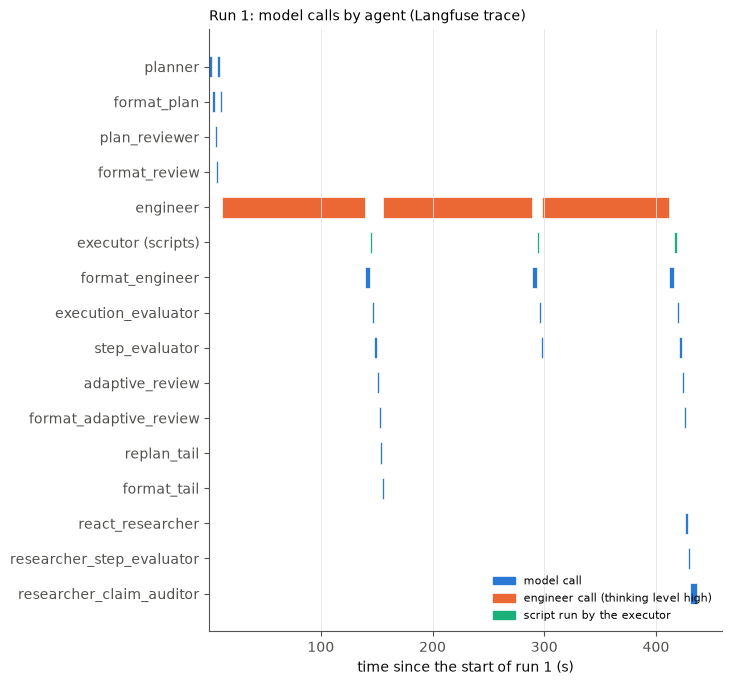

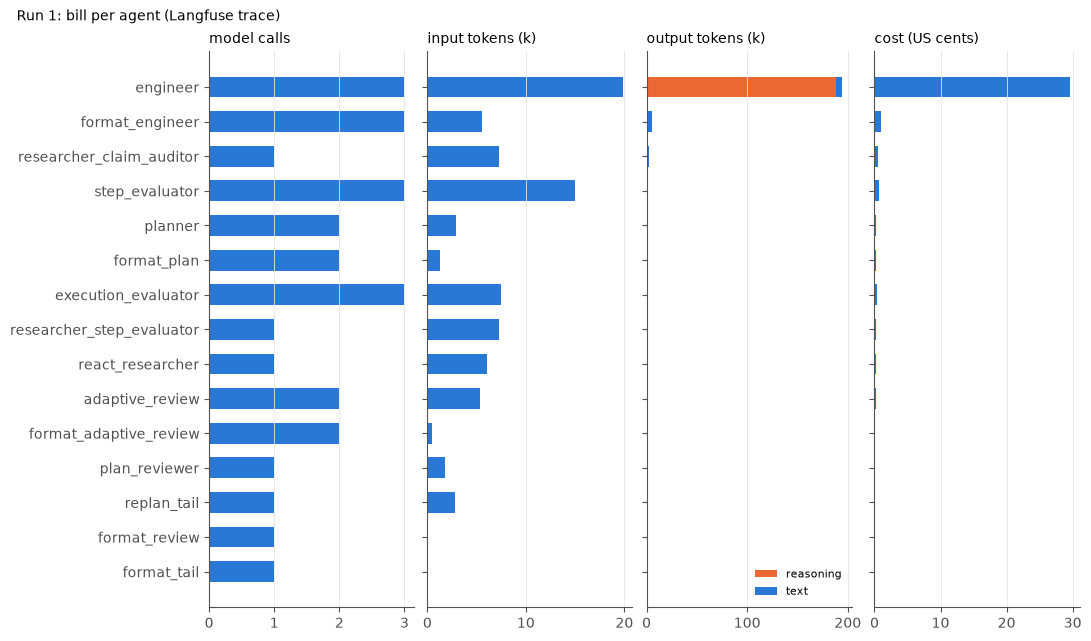

In [12]:
TRACED_RUN = "run1" in TRACE
SOURCE_NAME = "Langfuse trace" if TRACED_RUN else "local ledger"
TIMELINE_CALLS = TRACE["run1"]["calls"] if TRACED_RUN else RUNS_DONE[0]["calls"]
SCRIPTS = [sp for sp in TRACE["run1"]["spans"] if sp["name"] == "executor"] if TRACED_RUN else []


def plot_timeline(calls, scripts):
    calls = [c for c in calls if c["t0"] is not None]
    order = list(dict.fromkeys(c["agent"] for c in sorted(calls, key=lambda c: c["t0"])))
    if scripts:
        order.insert(order.index("engineer") + 1 if "engineer" in order else len(order), "executor (scripts)")
    fig, ax = plt.subplots(figsize=(7.2, 0.34 * len(order) + 1.3), layout="constrained")
    shortest = 0.004 * max(c["t1"] for c in calls)          # keep sub-second bars visible
    for c in calls:
        ax.barh(order.index(c["agent"]), max(c["t1"] - c["t0"], shortest), left=c["t0"], height=0.6,
                color=ORANGE if c["agent"] == "engineer" else BLUE, edgecolor="white", linewidth=0.5)
    for sp in scripts:
        ax.barh(order.index("executor (scripts)"), max(sp["t1"] - sp["t0"], shortest), left=sp["t0"], height=0.6,
                color=AQUA, edgecolor="white", linewidth=0.5)
    ax.set_yticks(range(len(order)), order)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("time since the start of run 1 (s)")
    ax.set_title(f"Run 1: model calls by agent ({SOURCE_NAME})", loc="left")
    handles = [plt.Rectangle((0, 0), 1, 1, color=BLUE, label="model call"),
               plt.Rectangle((0, 0), 1, 1, color=ORANGE, label="engineer call (thinking level high)")]
    if scripts:
        handles.append(plt.Rectangle((0, 0), 1, 1, color=AQUA, label="script run by the executor"))
    ax.legend(handles=handles, loc="lower right", fontsize=8)
    return fig


def plot_bill(calls, with_cost):
    table = bill(calls).sort_values("output_tokens")
    panels = 4 if with_cost else 3
    fig, axes = plt.subplots(1, panels, figsize=(2.3 * panels + 1.6, 0.32 * len(table) + 1.5), sharey=True,
                             layout="constrained")
    y = np.arange(len(table))
    axes[0].barh(y, table["calls"], height=0.6, color=BLUE)
    axes[0].set_title("model calls", loc="left")
    axes[1].barh(y, table["input_tokens"] / 1e3, height=0.6, color=BLUE)
    axes[1].set_title("input tokens (k)", loc="left")
    text_part = (table["output_tokens"] - table["reasoning_tokens"]).clip(lower=0) / 1e3
    axes[2].barh(y, table["reasoning_tokens"] / 1e3, height=0.6, color=ORANGE, label="reasoning")
    axes[2].barh(y, text_part, left=table["reasoning_tokens"] / 1e3, height=0.6, color=BLUE, label="text")
    axes[2].set_title("output tokens (k)", loc="left")
    axes[2].legend(loc="lower right", fontsize=8)
    if with_cost:
        axes[3].barh(y, table["cost_usd"] * 100, height=0.6, color=BLUE)
        axes[3].set_title("cost (US cents)", loc="left")
    axes[0].set_yticks(y, table.index)
    for ax in axes:
        ax.grid(axis="y", visible=False)
    fig.suptitle(f"Run 1: bill per agent ({SOURCE_NAME})", x=0.01, ha="left", fontsize=10)
    return fig


fig = plot_timeline(TIMELINE_CALLS, SCRIPTS)
save_figure(fig, "lg_trace_timeline")
plt.show()
fig = plot_bill(TIMELINE_CALLS, with_cost=TRACED_RUN)
save_figure(fig, "lg_bill_per_agent")
plt.show()

### Reading the trace in Langfuse

Open the project in Langfuse, select Traces and filter by the session printed above. Each run has two traces, `lecture01 run1 planning` and `lecture01 run1 execution`, grouped under one session.

- **Spans.** The tree of a trace follows the graph: one span per node that ran, such as `planner`, `run_step`, `engineer`, `executor` and `step_evaluator`, nested as the graphs are nested. Routing functions, such as `route_after_step_evaluator`, appear as spans of their own. The span of `executor` covers the time a script ran.
- **Generations.** Each model call is a generation inside the span of its node. It shows the prompt and the reply, the model, the input and output tokens with the reasoning tokens counted separately, the latency and, when the price is known, the cost.
- **Retries and loops.** An attempt that fails appears inside one `run_step` span as a repeated sequence: `engineer`, `format_engineer`, `executor`, `execution_evaluator` and, when the script ran, `step_evaluator`. The failed scripts are also kept in the working directory as `codebase/step_N_failure_K.py`. The plan review appears in the planning trace as a second `planner` generation after `plan_reviewer`.

The trace shows what each agent was given and what it returned. The ledger and the trace bill above give the totals.

In [13]:
def serialisable(run):
    keep = {k: v for k, v in run.items() if k not in ("work_dir", "calls", "report")}
    keep["report_excerpt"] = (run["report"] or "")[:1500]
    keep["totals"] = {"calls": len(run["calls"]), "input_tokens": sum(c["input_tokens"] for c in run["calls"]),
                      "output_tokens": sum(c["output_tokens"] for c in run["calls"]),
                      "reasoning_tokens": sum(c["reasoning_tokens"] for c in run["calls"])}
    keep["bill_local"] = bill(run["calls"]).to_dict(orient="index")
    keep["calls_local"] = run["calls"]
    if run["label"] in TRACE:
        keep["bill_trace"] = bill(TRACE[run["label"]]["calls"]).to_dict(orient="index")
        keep["trace_observations"] = TRACE[run["label"]]["observations"]
        keep["trace_generations"] = len(TRACE[run["label"]]["calls"])
        keep["trace_cost_usd"] = sum(r["cost_usd"] for r in TRACE[run["label"]]["calls"])
        keep["calls_trace"] = TRACE[run["label"]]["calls"]
        keep["spans_trace"] = TRACE[run["label"]]["spans"]
    return keep


MEASUREMENTS_LG = {
    "meta": {"date_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"), "model": MODEL,
             "versions": VERSIONS, "settings": SETTINGS, "runs": RUNS, "traced": TRACED, "tolerance": TOLERANCE},
    "reference": REFERENCE, "runs": [serialisable(run) for run in RUNS_DONE]}
(RESULTS_DIR / "measurements_lg.json").write_text(json.dumps(MEASUREMENTS_LG, indent=1, default=str) + "\n")
print("saved", RESULTS_DIR / "measurements_lg.json")

saved results/measurements_lg.json


## Exercises

#### Exercise 1: the vision review

(a) Set `vlm_enabled=True` in `make_context` and add a plotting requirement to `TASK`, for example the Hubble diagram with the fitted model.

(b) Run once and compare the bill per agent with that of the saved run. Which new agents appear in the trace, and which model do they use?

#### Exercise 2: retries in the trace

(a) Find a step with more than one attempt in a run's outcomes, and its failed scripts `codebase/step_N_failure_K.py` in the working directory.

(b) Find the same attempts in the Langfuse trace. Which evaluator sent each attempt back, and what did its verdict say?

#### Exercise 3: a stronger engineer

(a) Change only `engineer_model` to another model available to your key, and run once.

(b) Compare the number of attempts, the reasoning tokens and the wall time with the saved run.